<a href="https://colab.research.google.com/github/mashadiyevasabina/Python-Statistic-Instacard-Project/blob/main/Instacart_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Online Market Analizi Proyekti

#***Cədvəllər***
##***orders.csv : hər bir sətir Instacart tətbiqindəki bir sifarişə uyğundur***
###'order_id' : hər bir sifarişi unikal şəkildə eyniləşdirən ID nömrəsi
###'user_id' : hər bir müştəri hesabını unikal şəkildə eyniləşdirən ID nömrəsi
###'order_number' : bu müştərinin neçənci dəfə sifariş verdiyini göstərən say
###'order_dow' : sifarişin həftənin hansı günü verildiyi (hansı günün 0 olduğu dəqiq deyil)
###'order_hour_of_day' : sifarişin günün hansı saatında verildiyi
###'days_since_prior_order' : bu müştərinin əvvəlki sifarişindən sonra keçən günlərin sayı

##***products.csv : hər bir sətir müştərilərin ala biləcəyi unikal bir məhsula uyğundur***
###'product_id' : hər bir məhsulu unikal şəkildə eyniləşdirən ID nömrəsi
###'product_name' : məhsulun adı
###'aisle_id' : hər bir mağaza rəfi kateqoriyasını (grocery aisle category) unikal şəkildə eyniləşdirən ID nömrəsi
###'department_id' : hər bir mağaza şöbəsi kateqoriyasını (grocery department category) unikal şəkildə eyniləşdirən ID nömrəsi
##***order_products.csv : hər bir sətir bir sifarişə əlavə edilmiş bir məhsula uyğundur***
###'order_id' : hər bir sifarişi unikal şəkildə eyniləşdirən ID nömrəsi
###'product_id' : hər bir məhsulu unikal şəkildə eyniləşdirən ID nömrəsi
###'add_to_cart_order' : hər bir məhsulun səbətə hansı ardıcıllıqla əlavə edildiyi
###'reordered' : müştəri bu məhsulu əvvəllər heç vaxt sifariş etməyibsə 0, edibsə 1
##***aisles.csv: reonlar***
###'aisle_id' : hər bir mağaza rəfi kateqoriyasını unikal şəkildə eyniləşdirən ID nömrəsi
###'aisle' : rəfin (aisle) adı
##***departments.csv məhsul şöbəsi***
###'department_id' : hər bir mağaza şöbəsi kateqoriyasını unikal şəkildə eyniləşdirən ID nömrəsi
###'department' : şöbənin (department) adı


# ***Biz bu proyektdə***,

###*İnsanların həftənin hansı günü, günün hansı saatı daha çox alış-veriş etdiyini,*
###*İnsanların növbəti sifarişi verməzdən əvvəl nə qədər gözlədiklərini,*
###*Həftə içi və həftə sonu sifarişləri arasındakı fərqi,*
###*Ən çox yenidən sifariş edilən məhsulu,*
###*Top 20 Məhsulu və.s analiz edəcəyik*

In [91]:
#Əvvəlcə pandas kitabxanasını import edək
import pandas as pd

In [92]:
# Drive.ı import edək
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
# read_csv ilə cədvəllərimizi oxutduraq
orders         = pd.read_csv("/content/drive/MyDrive/python project/instacart_orders.csv", sep=';')
products       = pd.read_csv("/content/drive/MyDrive/python project/products (1).csv", sep=';')
departments    = pd.read_csv("/content/drive/MyDrive/python project/departments.csv", sep=';')
aisles         = pd.read_csv("/content/drive/MyDrive/python project/aisles.csv", sep=';')
order_products = pd.read_csv("/content/drive/MyDrive/python project/order_products.csv", sep=';')

# ***Orders cədvəlini nəzərdən keçirək və analiz üçün hazırlayaq***

In [4]:
orders.head(10)

,order_id,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order
0,1515936,183418,11,6,13,30.0
1,1690866,163593,5,5,12,9.0
2,1454967,39980,4,5,19,2.0
3,1768857,82516,56,0,20,10.0
4,3007858,196724,2,4,12,17.0
5,1843871,20084,5,0,11,15.0
6,2511640,148233,40,3,8,2.0
7,2521283,97711,2,0,18,22.0
8,2266494,34954,40,5,15,4.0
9,446014,15356,2,4,8,10.0


In [5]:
orders.shape

(478967, 6)

### ***Orders cədvəlimiz 478967 sətirdən və 6 sütundan ibarətdir***

In [6]:
#Describe
orders.describe()


,order_id,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order
count,4.789670e+05,478967.000000,478967.000000,478967.000000,478967.000000,450148.000000
mean,1.709947e+06,102966.537475,17.157808,2.775058,13.446676,11.101751
std,9.869480e+05,59525.328991,17.704688,2.045869,4.224986,9.189975
min,4.000000e+00,2.000000,1.000000,0.000000,0.000000,0.000000
25%,8.564685e+05,51414.000000,5.000000,1.000000,10.000000,4.000000
50%,1.709522e+06,102633.000000,11.000000,3.000000,13.000000,7.000000
75%,2.562990e+06,154419.000000,23.000000,5.000000,16.000000,15.000000
max,3.421079e+06,206209.000000,100.000000,6.000000,23.000000,30.000000


### ***Cədvəlin infosuna baxaq***

In [7]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 478967 entries, 0 to 478966
Data columns (total 6 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   order_id                478967 non-null  int64  
 1   user_id                 478967 non-null  int64  
 2   order_number            478967 non-null  int64  
 3   order_dow               478967 non-null  int64  
 4   order_hour_of_day       478967 non-null  int64  
 5   days_since_prior_order  450148 non-null  float64
dtypes: float64(1), int64(5)
memory usage: 21.9 MB


###***order_id sütunu integer tipindedir. days_since_proir_order sütununda 478967 sətirdən 450148 sətir null olmayan dəyərlərdir yəni 28819 null dəyər var. qalan bütün sütunlarda null dəyərlər yoxdur. Bəzi sütunlar üçün böyük ölçüdür.Yaddaşı düzgün idarə etmək və sürəti artırmaq üçün sutun tiplerini int64 dən int8 və int16 ya keçirək***

In [8]:
orders['days_since_prior_order'] = orders['days_since_prior_order'].astype('Int16')
orders['order_dow'] = orders['order_dow'].astype('int8')
orders['order_hour_of_day'] = orders['order_hour_of_day'].astype('int8')
orders['order_number'] = orders['order_number'].astype('int16')

### ***Yenidən infoya baxaq***

In [9]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 478967 entries, 0 to 478966
Data columns (total 6 columns):
 #   Column                  Non-Null Count   Dtype
---  ------                  --------------   -----
 0   order_id                478967 non-null  int64
 1   user_id                 478967 non-null  int64
 2   order_number            478967 non-null  int16
 3   order_dow               478967 non-null  int8 
 4   order_hour_of_day       478967 non-null  int8 
 5   days_since_prior_order  450148 non-null  Int16
dtypes: Int16(1), int16(1), int64(2), int8(2)
memory usage: 10.5 MB


### ***Yenidən infoya baxdım və yaddaşı 21.9 MB dan 10.5 MB a düşürərək qənaət etdik***

### ***İndi isə dublikatları tapaq və onları silək***

In [10]:
orders.duplicated().sum()


np.int64(15)

#### ***Orders cədvəlində 15 ədəd dublikat sətrimiz var. Bundan sonrakı sətirdə həmin dublikatları silək***

In [11]:
orders.drop_duplicates(inplace=True)

###***Yenidən dublikat sətirlər olub olmadığını yoxlayaq***

In [12]:
orders.duplicated().sum()

np.int64(0)

### ***Orders cədvəlində order_id lərin unikal dəyərlər almağı olduqca önəmlidir. Bu səbəbdən orders cədvəlində təkcə order_id lər də dublikat olub olmamağını araşdırq***

In [13]:
orders['order_id'].duplicated().sum()

np.int64(0)

### ***Dublikat order_id lər yoxdur. İndi isə cədvəlin shap().inə bir daha nəzər salaq***

In [14]:
orders.shape

(478952, 6)

### ***Artıq Orders cədvəlimiz 478952(daha öncə 478967) sətirdən və 6 sütundan ibarətdir***

### ***Hər həftənin Çərşənbə günləri saat 2:AM  də olunmuş sifariş saylarını tapaq***

In [15]:
# loc() funksiyasının içində & oreratoru ilə hər iki şərti bir birinə bağlayaq. Bizə cədvəl şəklində çıxaracaq

wednesday_orders=orders.loc[(orders['order_dow'] == 3) & (orders['order_hour_of_day'] == 2)]

# İndi isə sifariş sayını tapmaq üçün count()dan istifadə edək

wednesday_orders['order_id'].count()


np.int64(106)

#### ***Deməli həftənin 3 cü günləri saat 2 də cəmi 136 sifariş qeydə alınıb***

# ***Products cədvəlini nəzərdən keçirək və analiz üçün hazırlayaq***

In [16]:
products.head(10)

,product_id,product_name,aisle_id,department_id
0,1,Chocolate Sandwich Cookies,61,19
1,2,All-Seasons Salt,104,13
2,3,Robust Golden Unsweetened Oolong Tea,94,7
3,4,Smart Ones Classic Favorites Mini Rigatoni Wit...,38,1
4,5,Green Chile Anytime Sauce,5,13
5,6,Dry Nose Oil,11,11
6,7,Pure Coconut Water With Orange,98,7
7,8,Cut Russet Potatoes Steam N' Mash,116,1
8,9,Light Strawberry Blueberry Yogurt,120,16
9,10,Sparkling Orange Juice & Prickly Pear Beverage,115,7


In [17]:
products.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49694 entries, 0 to 49693
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   product_id     49694 non-null  int64 
 1   product_name   48436 non-null  object
 2   aisle_id       49694 non-null  int64 
 3   department_id  49694 non-null  int64 
dtypes: int64(3), object(1)
memory usage: 1.5+ MB


### ***Bizə vacib olan Product_id int tipində olmasıdır. və int tipindədir. product_name sütünunda 49694 sətirdən 48436 sətir nul deyil. qalan sütunlarda null dəyərlər yoxdur. Product_name sütünü obyekt tipindədir. irəlidə stringə aid əməliyyatları rahat apara bilək deyə string tipinə keçmək olar***


In [18]:
# Product_name sutun sitipi stringə çevirə bilərik
products['product_name'] = products['product_name'].astype('string')


In [19]:
# yenidən info() ya baxaq
products.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49694 entries, 0 to 49693
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   product_id     49694 non-null  int64 
 1   product_name   48436 non-null  string
 2   aisle_id       49694 non-null  int64 
 3   department_id  49694 non-null  int64 
dtypes: int64(3), string(1)
memory usage: 1.5 MB


In [20]:
products.shape

(49694, 4)

###***İndi isə dublikatları tapaq və onları silək***

In [21]:
products.duplicated().sum()


np.int64(0)

### ***Product cədvəlində dublikat sətirlərimiz yoxdu***

###***Products cədvəlində product_id lərin unikal dəyərlər almağı olduqca önəmlidir. Bu səbəbdən products cədvəlində təkcə product_id lər də dublikat olub olmamağını araşdırq***

In [22]:
products['product_id'].duplicated().sum()


np.int64(0)

### ***product_id sutununda dublikat dəyərlər yoxdu***

### ***product_name sütununda dublikatlar olub olmadığını yoxlayaq***

In [23]:
# Əvvəllcə stringə çevirib sonra dublikatların cəmini axtaraq
products['product_name'].str.lower().duplicated().sum()



np.int64(1361)

### ***1361 dublikat məhsul adı var. İndi isə dublikat məhsul adları arasında missing value olmayanları seçək***

In [24]:

# Hr iki şərti & opreratoru ilə birləşdirək
not_missing_produucts=products[(products['product_name'].notnull()) & (products['product_name'].str.lower().duplicated())]
not_missing_produucts



,product_id,product_name,aisle_id,department_id
2058,2059,Biotin 1000 Mcg,47,11
5455,5456,Green Tea With Ginseng and Honey,96,20
5558,5559,Cream Of Mushroom Soup,69,15
7558,7559,Cinnamon Rolls with Icing,105,13
9037,9038,American Cheese slices,21,16
...,...,...,...,...
49689,49690,HIGH PERFORMANCE ENERGY DRINK,64,7
49690,49691,ORIGINAL PANCAKE & WAFFLE MIX,130,14
49691,49692,ORGANIC INSTANT OATMEAL LIGHT MAPLE BROWN SUGAR,130,14
49692,49693,SPRING WATER BODY WASH,127,11


#***Departments cədvəlini nəzərdən keçirək və analiz üçün hazırlayaq***

In [25]:
departments.head(10)

,department_id,department
0,1,frozen
1,2,other
2,3,bakery
3,4,produce
4,5,alcohol
5,6,international
6,7,beverages
7,8,pets
8,9,dry goods pasta
9,10,bulk


In [26]:
departments.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   department_id  21 non-null     int64 
 1   department     21 non-null     object
dtypes: int64(1), object(1)
memory usage: 468.0+ bytes


###***Hər iki sütunda null dəyərlər yoxdur. Department_id sütünu integer tipdir. Burada dəyişiklik etmirik. department sutununda isə adlar olduğu üçün stringə keçə bilərik***

In [27]:
departments['department'] = departments['department'].astype('string')


In [28]:
departments.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   department_id  21 non-null     int64 
 1   department     21 non-null     string
dtypes: int64(1), string(1)
memory usage: 468.0 bytes


###***department sütununda dublikat dəyərlər olub olmadığına baxaq***

In [29]:
departments['department'].str.lower().duplicated().sum()

np.int64(0)

### ***Dublikat department yoxdur***

### ***department_id sütununda dublikat dəyərlər olub olmadığını yoxlayaq***

In [30]:
departments['department_id'].duplicated().sum()

np.int64(0)

###***Dublikat department yoxdur***

#***Aisles cədvəlini nəzərdən keçirək və analiz üçün hazırlayaq***

In [31]:
aisles.head(10)

,aisle_id,aisle
0,1,prepared soups salads
1,2,specialty cheeses
2,3,energy granola bars
3,4,instant foods
4,5,marinades meat preparation
5,6,other
6,7,packaged meat
7,8,bakery desserts
8,9,pasta sauce
9,10,kitchen supplies


In [32]:
aisles.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 134 entries, 0 to 133
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   aisle_id  134 non-null    int64 
 1   aisle     134 non-null    object
dtypes: int64(1), object(1)
memory usage: 2.2+ KB


### ***Aisles cədvəlində hər iki sütunda null dəyərlər yoxdur. İD sütunu int tipindədir. aisle sütununu string tipinə çevirə bilərik***

In [33]:
aisles['aisle'] = aisles['aisle'].astype('string')

In [34]:
aisles.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 134 entries, 0 to 133
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   aisle_id  134 non-null    int64 
 1   aisle     134 non-null    string
dtypes: int64(1), string(1)
memory usage: 2.2 KB


###***Aisle sütununda dublikat dəyərlər olub olmadığına baxaq***

In [35]:
aisles['aisle'].str.lower().duplicated().sum()

np.int64(0)

###***Dublikat dəyərlər yoxdur***


###***Aisle_id sütununda dublikat dəyərlər olub olmadığına baxaq***

In [36]:
aisles['aisle_id'].duplicated().sum()

np.int64(0)

#***Order_products cədvəlini nəzərdən keçirək və analiz üçün hazırlayaq***

In [37]:
order_products.head(10)

,order_id,product_id,add_to_cart_order,reordered
0,2141543,11440,17.0,0
1,567889,1560,1.0,1
2,2261212,26683,1.0,1
3,491251,8670,35.0,1
4,2571142,1940,5.0,1
5,2456893,21616,4.0,1
6,644579,12341,5.0,1
7,2231852,44925,10.0,1
8,3185766,36259,14.0,1
9,420019,23315,4.0,1


In [38]:
# Data böyük olduğu üçün show_counts=True arqumentini əlavə edək
order_products.info(show_counts=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4545007 entries, 0 to 4545006
Data columns (total 4 columns):
 #   Column             Non-Null Count    Dtype  
---  ------             --------------    -----  
 0   order_id           4545007 non-null  int64  
 1   product_id         4545007 non-null  int64  
 2   add_to_cart_order  4544171 non-null  float64
 3   reordered          4545007 non-null  int64  
dtypes: float64(1), int64(3)
memory usage: 138.7 MB


### ***Bu cədvəldə id sütunlar integer tipindədir. add_to_card_order sütununda 836 nul dəyər var qalan heç bir sütunda null dəyərlər yoxdur***

### ***Bütöv cədvəldə dublikat sətirləri araşdıraq***

In [39]:
order_products.duplicated().sum()

np.int64(0)

### ***Ümumi cədvəldə dublikat sətirlər yoxdur. Lakin bəzi aldadıcı dublikatlar ola bilər məsələn***
### ***1. Bir sifarişdə, eyni mehsulun iki fərqli "səbətə atma sırası"(add_to_card_order) ola bilməz. sadəcə məhsulun sayı dəyişə bilər. əgər səhvən bu olubsa sistem onu dublikat kimi yox fərqli sətir kimi qəbul edəcək.Bir sifarişdə bir məhsulun adının sadəcə bir dəfə düşməsini yoxlamaq üçün  duplicate() funksiyasında sadəcə order_id və Product_id yoxlayacam***


In [40]:
tricky_add_to_card_duplicates1=order_products[['order_id', 'product_id']].duplicated().sum()
tricky_add_to_card_duplicates1

np.int64(0)

### ***burada dublikatlar yoxdur. Deməli hər sifarişdə hər məhsulun adı cəmi bir dəfə iştirak edib***

### ***2. Səbətə atma sırası eyni olan iki fərqli məhsul ola bilməz.Əgər səbətə atılan məhsulun eyni sıra nömrəsi və səhvən fərqli ad göstərirsə sistem bunu da fərqli sətir kimi görüb dublikat saymayacaq.  bunun üçün duplicate() funksiyasinda Sadece oreder_id və add_to_card sütunlarını yoxlayıram***

In [41]:
tricky_add_to_card_duplicates2=order_products[['order_id', 'add_to_cart_order']].duplicated().sum()
tricky_add_to_card_duplicates2

np.int64(766)

### ***Burada əsas səbəb, add_to_cart_order sütunundakı missing value-lar ola biler. NaN dəyərlər təkrar kimi görünə bilər. misisng valuelər yoxlanmalıdır***

#***Cədvəllərimizdə missing valueləri tapaq və redaktə edək***


### ***Hər bir cədvəlin ayrıca infosuna baxanda sadəcə 3 cədvəldə: Products, Orders və Order_products cədvəllərində missinng valuelər olduğunu gördük. hər bir cədvəl üçün bunu ayrıca araşdıraq***

### ***Products cədvəli***

In [42]:
# Ümumi cədvəldə missing valueləri tapaq
products.isna().sum()

,0
product_id,0
product_name,1258
aisle_id,0
department_id,0


### ***product_name sütununda 1258 missing value var. Əvvəlcə Bu sütundakı missing valuelərə nəzər salaq***

In [43]:
missing_products=products[products['product_name'].isna()]
missing_products



,product_id,product_name,aisle_id,department_id
37,38,<NA>,100,21
71,72,<NA>,100,21
109,110,<NA>,100,21
296,297,<NA>,100,21
416,417,<NA>,100,21
...,...,...,...,...
49552,49553,<NA>,100,21
49574,49575,<NA>,100,21
49640,49641,<NA>,100,21
49663,49664,<NA>,100,21


### ***Görünür ki missing valuelər ən çox aisle_id 100 reonunda və 21 ci departmentdədir. indi isə baxaq ki bu halda aisle_id və department_id sütununda başqa dəyərlər də varmı***

In [44]:
missing_products['aisle_id'].unique()

array([100])

In [45]:
missing_products['department_id'].unique()

array([21])

### ***Başqa dəyərlər yoxdur deməli sadəcə 21ci departmentin 100cü reonundakı məshulların adları boşdur***

### ***Bu departmeni və reonu araşdıraq***
### ***Cədvəlləri birləşdirərək araşdırma etmək üçün aises və departments cədvəllərində ortaq sütun yoxdur ona görə də products cədvəli ilə birgə birləşdircəm***

In [46]:
# merge() funksiyasından istifadə edərək left join edirik ki, product cədvəlindəki heç bir məlumat itməsin

birləşmiş_cədvəl = (products.merge(aisles, on='aisle_id', how='left').merge(departments, on='department_id', how='left'))

# Daha sonra 21 ci department və 100cu reon şərlərini & operatoru ilə bağlayıb həmin hissəyə baxırıq

birləşmiş_cədvəl[(birləşmiş_cədvəl['department_id']==21) & (birləşmiş_cədvəl['aisle_id']==100)]


,product_id,product_name,aisle_id,department_id,aisle,department
37,38,<NA>,100,21,missing,missing
71,72,<NA>,100,21,missing,missing
109,110,<NA>,100,21,missing,missing
296,297,<NA>,100,21,missing,missing
416,417,<NA>,100,21,missing,missing
...,...,...,...,...,...,...
49552,49553,<NA>,100,21,missing,missing
49574,49575,<NA>,100,21,missing,missing
49640,49641,<NA>,100,21,missing,missing
49663,49664,<NA>,100,21,missing,missing


### ***Deməli həmin department və reonun adları "missing" olaraq qeyd olunduğundan həmin məhsulların adları da cədvəldə boş qalıb. bundan əvvəl departments və aisles cədvəllərini araşdırdıqda missing valueni göstərməməsinin səbəbi cədvəldə həmin xananı boş qoymaq əvəzinə manual olaraq "missing" yazılmasıdır***

### ***Bu səbəbdən products cədvəlindəki boş dəyərləri "unknown" ilə dolduraq***

In [47]:
# Fillna() metodundan istifadə edərək dolduraq
products.fillna('unknown', inplace=True)

# Və boş dəyərlərin dolub dolmadığını yenidən yoxlayaq
products.isna().sum()


,0
product_id,0
product_name,0
aisle_id,0
department_id,0


### ***isna() metodu bizə hər sütunda 0 sayda boş dəyər olduğunu göstərdi, deməli cədvəlimiz doldu***

## ***Orders cədvəli***

In [48]:
orders.isna().sum()

,0
order_id,0
user_id,0
order_number,0
order_dow,0
order_hour_of_day,0
days_since_prior_order,28817


### ***Sadəcə days_since_perior_order sütununda(əvvəlki sifarişdə sonra keçən günlər) missing valuelər olduğuna görə bu sütundakı missing valueləri araşdıraq***

In [49]:
missing_value1=orders[orders['days_since_prior_order'].isna()]
missing_value1

,order_id,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order
28,133707,182261,1,3,10,<NA>
96,787445,25685,1,6,18,<NA>
100,294410,111449,1,0,19,<NA>
103,2869915,123958,1,4,16,<NA>
104,2521921,42286,1,3,18,<NA>
...,...,...,...,...,...,...
478895,2589657,205028,1,0,16,<NA>
478896,2222353,141211,1,2,13,<NA>
478922,2272807,204154,1,1,15,<NA>
478926,2499542,68810,1,4,19,<NA>


###### ***Çox təbiidir ki, Burada boş dəyərlər ən çox order_number==1 sütunundadır. Bu normaldır çünki, ilk sifariş olduğu üçün əvvəlki sifariş və keçən günlər yoxdur. araşdıraq ki order_id sütununda başqa dəyər də varmı***

In [50]:
missing_value1['order_number'].unique()


array([1], dtype=int16)

### ***1 dən başqa dəyər olmadığı üçün buradakı missing value.ləri doldurmağa ehtiyac yoxdu.***

## ***Order_products cədvəli***

---



In [51]:
order_products

,order_id,product_id,add_to_cart_order,reordered
0,2141543,11440,17.0,0
1,567889,1560,1.0,1
2,2261212,26683,1.0,1
3,491251,8670,35.0,1
4,2571142,1940,5.0,1
...,...,...,...,...
4545002,577211,15290,12.0,1
4545003,1219554,21914,9.0,0
4545004,692640,47766,4.0,1
4545005,319435,691,8.0,1


In [52]:
order_products.duplicated().sum()

np.int64(0)

In [53]:
# Ümumi order_products cədvəlində nul dəyərləri axtaraq
order_products.isna().sum()

,0
order_id,0
product_id,0
add_to_cart_order,836
reordered,0


### ***Sadəcə add_to_cart_order sütununda 836 missing valuelər var. Həmin sütunu araşdıraq***

In [54]:
missing_value2=order_products[order_products['add_to_cart_order'].isna()]
missing_value2


,order_id,product_id,add_to_cart_order,reordered
737,2449164,5068,NaN,0
9926,1968313,43867,NaN,0
14394,2926893,11688,NaN,0
16418,1717990,4142,NaN,0
30114,1959075,42828,NaN,1
...,...,...,...,...
4505662,1800005,7411,NaN,0
4511400,1633337,260,NaN,0
4517562,404157,9517,NaN,0
4534112,1673227,17835,NaN,0


### ***missing valuelər olan sifarişlərin unikal İd lərini saxlayıb lazımi şöbələrə araşdırılmağa yönləndirəcəm***

In [55]:
missing_addtocard=missing_value2['order_id'].unique()
missing_addtocard


array([2449164, 1968313, 2926893, 1717990, 1959075,  844733,   61355,
        936852,  264710, 1564093,  129627,  293169, 2849370, 1386261,
       3308010,  903110, 2136777, 3347453, 1888628,  165801, 2094761,
       1038146, 2997021,  813364, 2256933,  171934, 2409109, 1730767,
       1169835,  733526,  404157, 3125735,  747668, 1800005, 1961723,
        871281,  388234, 1648217, 1477139,  102236, 1021563, 1832957,
       2721963,  678116, 1220886, 1673227, 2999801, 1633337, 2470674,
       2625444, 1677118, 2479011, 3383594, 1183255, 1713430, 2652650,
       1598369, 1916118,  854647, 1302315,  888470,  180546, 2621907,
       1308785, 2729254,    9310, 2170451, 2979697, 1625713, 1529171])

### ***İndi isə bir sifarişdə ən az və ən çox neçə ədəd fərqli məhsul sifariş olunduğuna baxaq***

In [56]:
# Bunun üçün min() və max() metodlarından istifadə edək

print(f'min value is {order_products["add_to_cart_order"].min()}')
print(f'max value is {order_products["add_to_cart_order"].max()}')


min value is 1.0
max value is 64.0


### ***Deməli bir sifarişdə ən az 1, ən çox 64 məhsul sifariş verilib***

### ***Ən azı bir missing valuesi olan sifarişlərdə  ümumi məhsul sayının 64 dən çox olub olmamasini araşdıraq***

In [57]:
product_counts = (
    order_products[order_products['add_to_cart_order'].isna()]
    .groupby('order_id')['product_id']
    .count()
    .reset_index(name='product_count')
    .sort_values(by='product_count', ascending=False)
)

product_counts

,order_id,product_count
1,61355,63
67,3308010,51
49,2136777,44
5,171934,40
45,1959075,34
...,...,...
18,888470,1
50,2170451,1
60,2729254,1
56,2621907,1


### ***Bəli 70 ədəd sifarişdə missing value var***

### ***Misiisng valueləri 999 ilə dolduraq və sütun tipini integere çevirək***


In [58]:

order_products['add_to_cart_order'].fillna(999, inplace=True)
order_products['add_to_cart_order'].astype(int)

order_products.isna().sum()


/tmp/ipykernel_6484/79911197.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  order_products['add_to_cart_order'].fillna(999, inplace=True)


,0
order_id,0
product_id,0
add_to_cart_order,0
reordered,0


### ***Artıq heç bir missing value qalmadı***



##***[A1] Orders cədvəllərindəki 'order_hour_of_day' və 'order_dow' dəyərlərinin məntiqli olub olmadınğını araşdıraq (məsələn, 'order_hour_of_day' 0-dan 23-ə, 'order_dow' isə 0-dan 6-ya qədər dəyişir)***

In [59]:
# max() və Min() funksiyalarının kömyindən istifadə edərək order_hour_of_day sütununda kənaraçıxma dəyərlərinə baxaq

print(f' minimum order_hour_of_day is  {orders['order_hour_of_day'].min()}')
print(f' maximum order_hour_of_day is  {orders['order_hour_of_day'].max()}')

# Indi isə order_dow sütunu üçün eynisni edək

print(f' minimum order_dow is  {orders['order_dow'].min()}')
print(f' maximum order_dow is  {orders['order_dow'].max()}')


 minimum order_hour_of_day is  0
 maximum order_hour_of_day is  23
 minimum order_dow is  0
 maximum order_dow is  6


### ***Bu sütunlrın dəyərlərində hər hansı bir kənaraçıxma yoxdur***

###***[A2]İnsanlar günün hansı saatlarında daha çox alış-veriş edirlər? Bunu öyrənmək üçün Orders cədvəlindən və order_hour_of_day sütunundan istifadə edəcəyik***

In [60]:
# Value_count() metodu order hour of day sütunda bir dəyərdən  neçə ədəd təkrarlandığının sayını tapacaq. və sort_index edekərk saatları sıra ilə yazdıraq
saat_analizi = orders['order_hour_of_day'].value_counts().sort_index()
saat_analizi

,count
order_hour_of_day,
0,3180
1,1763
2,989
3,770
4,765
5,1371
6,4215
7,13043
8,25024


### ***Bu cədvələ Bar Chart qrafikində baxaq***

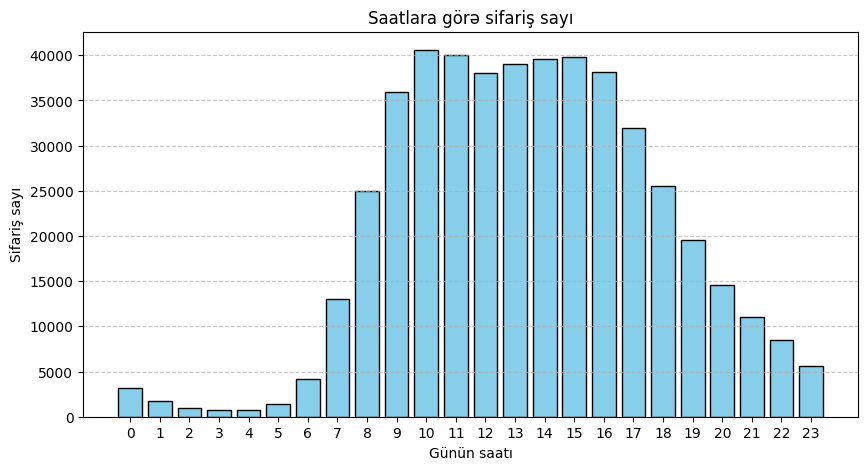

In [61]:
import matplotlib.pyplot as plt
saat_analizi = orders['order_hour_of_day'].value_counts().sort_index()
plt.figure(figsize=(10, 5))
plt.bar(saat_analizi.index, saat_analizi.values, color='skyblue', edgecolor='black')
plt.title('Saatlara görə sifariş sayı')
plt.xlabel('Günün saatı')
plt.ylabel('Sifariş sayı')
plt.xticks(range(0, 24))
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

### ***Buradan görünür ki insanlar səhər və günorta saatlarında, saat 9 16 aralığında daha çox alış veriş edirlər. Ən pik göstərici saat 10 dadır. insanların əksəriyyəti nahar və axşam yemeyi hazırlamaq və s. üçün saat 10 da alış veriş etməyi üstün tutur.***

### ***[A3] Baxaq ki, İnsanlar həftənin hansı günü daha çox ərzaq alış-verişi edirlər? Bunun Üçün orders cədvəlinin order_dow swtunundan istifadə edəcəyik***

In [62]:
# order_hour_of_day sütunu üçün tətbiq etdiyimiz qaydanı burada da tətbiq edirik
gün_analizi = orders['order_dow'].value_counts().sort_index()
gün_analizi

,count
order_dow,
0,84090
1,82185
2,65833
3,60897
4,59810
5,63488
6,62649


### ***Gəlin bu cədvələ bar chart qrafikində baxaq***

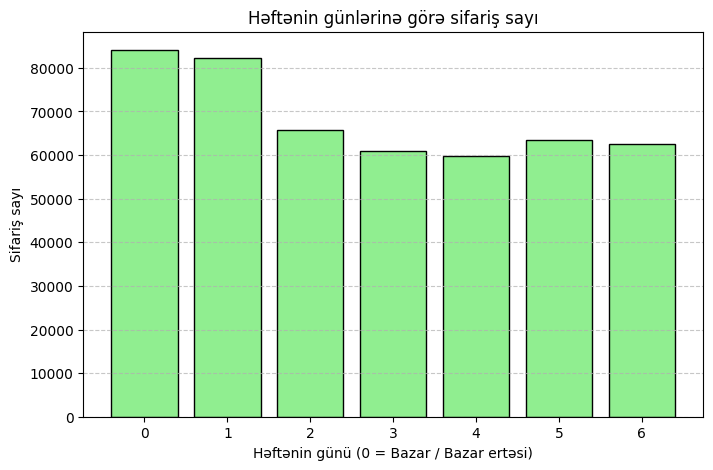

In [63]:
gün_analizi = orders['order_dow'].value_counts().sort_index()
plt.figure(figsize=(8, 5))
plt.bar(gün_analizi.index, gün_analizi.values, color='lightgreen', edgecolor='black')
plt.title('Həftənin günlərinə görə sifariş sayı')
plt.xlabel('Həftənin günü (0 = Bazar / Bazar ertəsi)')
plt.ylabel('Sifariş sayı')
plt.xticks(gün_analizi.index)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()

### ***Qrafikdən görünür ki insanlar daha çox həftənin bazar günü alış veriş edirlər. Bu həmin gün insanların asudə vaxtının çox olması, Növbəti iş və dərs həftəsi üçün bazar günündən hazırlq görülməsi ilə bağlı ola bilər***

### ***[A4] İnsanlar digər sifarişi vermək üçün nə qədər müddət gözləyir?***
### ***Orders cədvəlindən və describe() metodundan istifadə edək***

In [64]:
orders.describe()

,order_id,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order
count,4.789520e+05,478952.000000,478952.000000,478952.000000,478952.000000,450135.0
mean,1.709953e+06,102966.654911,17.157563,2.775051,13.447034,11.101814
std,9.869537e+05,59525.292863,17.704457,2.045901,4.224567,9.190004
min,4.000000e+00,2.000000,1.000000,0.000000,0.000000,0.0
25%,8.564698e+05,51413.750000,5.000000,1.000000,10.000000,4.0
50%,1.709521e+06,102633.000000,11.000000,3.000000,13.000000,7.0
75%,2.563002e+06,154419.000000,23.000000,5.000000,16.000000,15.0
max,3.421079e+06,206209.000000,100.000000,6.000000,23.000000,30.0


### ***Görünür ki, ikinci dəfə sifariş verən müştərilər ən tez həmin gün ən gec isə bir ay müddətində yenidən sifariş verir və ortalama olaraq 11 gündən sonra sifariş verirlər***

# ***[B]***

### ***[B1] Çərşənbə və şənbə günləri "order_hour_of_day" paylanmalarında fərq varmı? Hər iki gün üçün histoqramları çəkin və gördüyünüz fərqləri təsvir edin.***

In [65]:
# Cədvəldən 3 və 6 cı günləri seçirik
günlər = orders[orders['order_dow'].isin([3, 6])]

# yanaşı şəkildə müqayisəsini görmək üçün pivot table() istifadə edək
cedvel_muqayise = günlər.pivot_table(index='order_hour_of_day',
                                     columns='order_dow',
                                     aggfunc='size')

cedvel_muqayise


order_dow,3,6
order_hour_of_day,,
0,373,464
1,215,254
2,106,177
3,101,125
4,108,118
5,170,161
6,643,451
7,1732,1619
8,3125,3246


### ***Gəlin bu cədvələ histogram qrafikində baxaq***

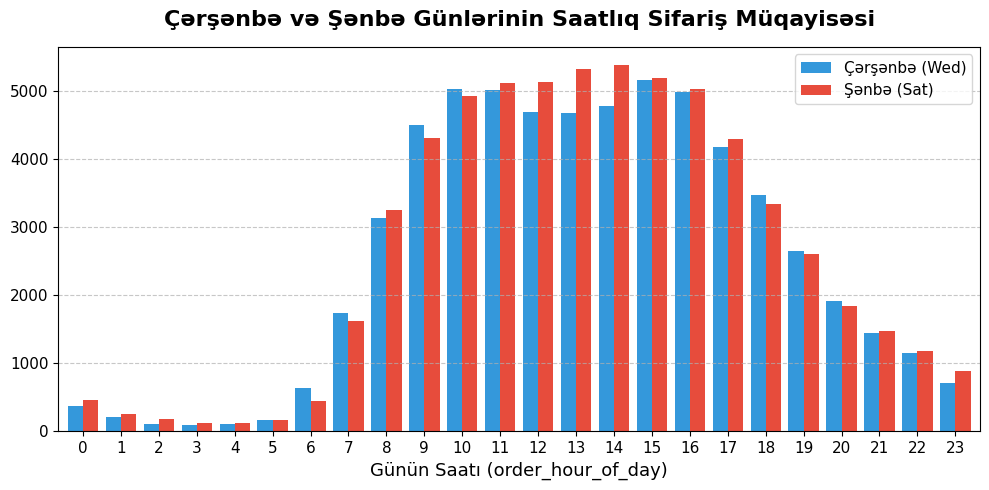

In [66]:
cedvel_muqayise.columns = ['Çərşənbə (Wed)', 'Şənbə (Sat)']
ax = cedvel_muqayise.plot(kind='bar', figsize=(10, 5), width=0.8, color=['#3498db', '#e74c3c'])
plt.title('Çərşənbə və Şənbə Günlərinin Saatlıq Sifariş Müqayisəsi', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Günün Saatı (order_hour_of_day)', fontsize=13)
plt.xticks(rotation=0, fontsize=11)
plt.yticks(fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(fontsize=11, loc='upper right')
plt.tight_layout()
plt.show()

### Qrafikdən görünür ki həftə sonu da həftə içi kimi ən çox səhər və günorta saatlarında alış veriş edilir. Şənbə günü ən pik aışveriş saatı 14.00 (5375)Çərşənbə günü isə ən pik alış veriş saatı 15.00(5163) dur. Həftə sonu gecə saatlarındakı alış veriş sayı həftə içinə nisbətən daha çoxdur. Bu insanların həftə sonu daha gec yatdığı ilə əlaqəli ola bilər

### ***[B2] Müştərilərin sifariş sayının paylanmasını tapaq***

In [67]:
# 1. Hər müştərinin sifariş sayını tapırıq

musteri_sifaris_sayı = orders.groupby('user_id')['order_id'].nunique().reset_index()
musteri_sifaris_sayı.columns = ['user_id', 'order_count']
musteri_sifaris_sayı

# İndi isə hansı saydan neçə dənə olduğunu tapaq

paylanma = musteri_sifaris_sayı['order_count'].value_counts().sort_index()
paylanma

,count
order_count,
1,55357
2,36508
3,21547
4,13498
5,8777
6,6012
7,4240
8,3019
9,2152


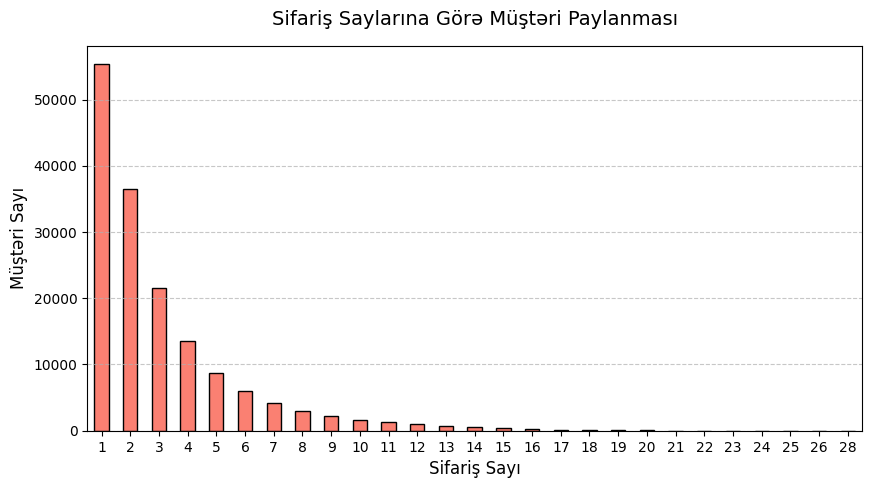

In [68]:
plt.figure(figsize=(10, 5))
paylanma.plot(kind='bar', color='salmon', edgecolor='black')
plt.title('Sifariş Saylarına Görə Müştəri Paylanması', fontsize=14, pad=15)
plt.xlabel('Sifariş Sayı', fontsize=12)
plt.ylabel('Müştəri Sayı', fontsize=12)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

### ***Deməli sadəcə 1 dəfə tətbiqdən alış veriş edən müştəri sayı 55357 dir. tətbiqdən ən çox istifadə edən müştərinin maksimum fərqli sifariş sayı 28 dir. Sadəcə bir dəfə alış veriş edib dayanan müştərilər üçün cəlbedici kompaniyalar və təkliflər etməyi məsləhər görmək olar. ən çox sifariş edən müştəriləri də daim saxlamaq üçün artan bonus taarifləri və s təklif etmək olar***

### ***[B3] Ən çox satılan 20 məhsul hansılardır (onların id.sini  və adını göstərin)***

### ***Bunun üçün orders və order_product cədvəllərindən istifadə edəcəyik***

In [69]:
# merge() funksiyasından istifadə edərək left join edirik ki, product cədvəlindəki heç bir məlumat itməsin

birləşmiş_cədvəl = (products.merge(aisles, on='aisle_id', how='left').merge(departments, on='department_id', how='left'))

# Daha sonra 21 ci department və 100cu reon şərlərini & operatoru ilə bağlayıb həmin hissəyə baxırıq

birləşmiş_cədvəl[(birləşmiş_cədvəl['department_id']==21) & (birləşmiş_cədvəl['aisle_id']==100)]

,product_id,product_name,aisle_id,department_id,aisle,department
37,38,unknown,100,21,missing,missing
71,72,unknown,100,21,missing,missing
109,110,unknown,100,21,missing,missing
296,297,unknown,100,21,missing,missing
416,417,unknown,100,21,missing,missing
...,...,...,...,...,...,...
49552,49553,unknown,100,21,missing,missing
49574,49575,unknown,100,21,missing,missing
49640,49641,unknown,100,21,missing,missing
49663,49664,unknown,100,21,missing,missing


In [70]:


# Əvvəlcə Ən çox satılan ilk 20 məhsulun id sini tapaq bunun üçün value_countdans() dan istifadə edək

top_20 = order_products['product_id'].value_counts().head(20).reset_index()

# İndi birləşdiririk

merged=products.merge(top_20, on='product_id')

# counta görə çoxdan aza sıralayaq

merged=merged.sort_values(by='count', ascending= False)
merged





,product_id,product_name,aisle_id,department_id,count
7,24852,Banana,24,4,66050
2,13176,Bag of Organic Bananas,24,4,53297
4,21137,Organic Strawberries,24,4,37039
5,21903,Organic Baby Spinach,123,4,33971
16,47209,Organic Hass Avocado,24,4,29773
18,47766,Organic Avocado,24,4,24689
17,47626,Large Lemon,24,4,21495
3,16797,Strawberries,24,4,20018
9,26209,Limes,24,4,19690
10,27845,Organic Whole Milk,84,16,19600


### ***Deməli ən çox satılan məhsul banan imiş (66050)***

#***[C]***

### ***[C1] İnsanlar adətən bir sifarişdə neçə məhsul alırlar? Paylanma necə görünür?***

In [71]:
order_products

,order_id,product_id,add_to_cart_order,reordered
0,2141543,11440,17.0,0
1,567889,1560,1.0,1
2,2261212,26683,1.0,1
3,491251,8670,35.0,1
4,2571142,1940,5.0,1
...,...,...,...,...
4545002,577211,15290,12.0,1
4545003,1219554,21914,9.0,0
4545004,692640,47766,4.0,1
4545005,319435,691,8.0,1


In [72]:
product_per_order=order_products['product_id'].value_counts().sum()/order_products['order_id'].nunique()
product_per_order




np.float64(10.098983215049127)

### ***Gəlin buna histogram qrafikində baxaq***

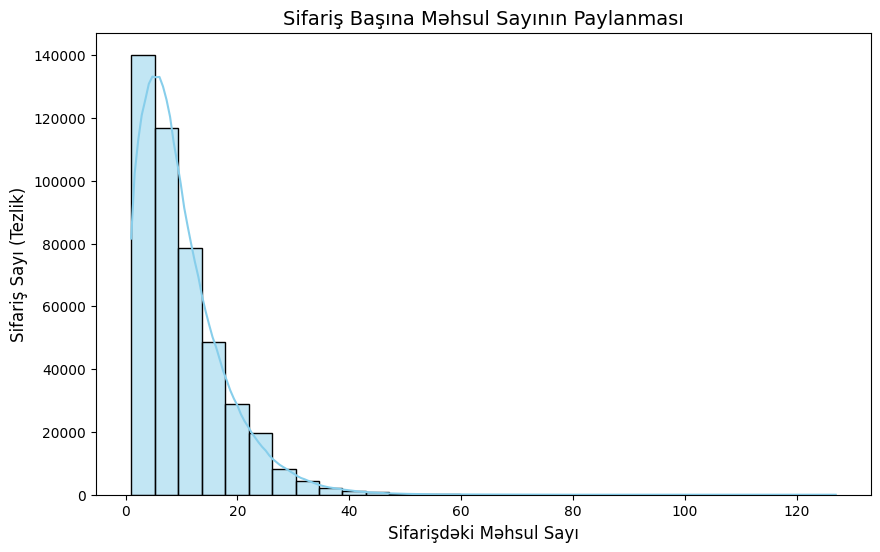

In [73]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Hər sifarişdə neçə məhsul olduğunu hesablayırıq
products_per_order = order_products.groupby('order_id')['product_id'].count()

# 2. Histoqram qrafikini qururuq
plt.figure(figsize=(10, 6))
sns.histplot(products_per_order, bins=30, kde=True, color='skyblue')

# 3. Başlıq və ox adlarını əlavə edirik
plt.title('Sifariş Başına Məhsul Sayının Paylanması', fontsize=14)
plt.xlabel('Sifarişdəki Məhsul Sayı', fontsize=12)
plt.ylabel('Sifariş Sayı (Tezlik)', fontsize=12)

# Ekran çıxarırıq
plt.show()

### ***Aldıq ki müştərilər hər sifarişdə ortalama 10 məhsul sifariş verirlər***

###***"Sifariş saylarının böyük hissəsi paylanmanın quyruq (tail) hissəsində yerləşir. Quyruqdan kənar hissəni daha aydın görmək üçün quyruq hissəsindən kəsilmə (cutoff) həddi kimi bir dəyər seçək və yalnız həmin həddən az elementi olan sifarişlərin qrafikini quraq. 35 elementlik sifariş ölçüsü bu məqsəd üçün quyruq hissəsində kifayət qədər dərində yerləşir."***

In [74]:
# əvvəlcə hər bir order_id yə düşən  məhsul sayını tapaq
order_sizes = order_products['order_id'].value_counts()
order_sizes
filtered_order_sizes = order_sizes[order_sizes < 35]
filtered_order_sizes


,count
order_id,
1803626,34
916161,34
1711144,34
1588622,34
1859303,34
...,...
1933026,1
2528686,1
2273859,1


###***indi bu hissənin qrafikinə baxaq***


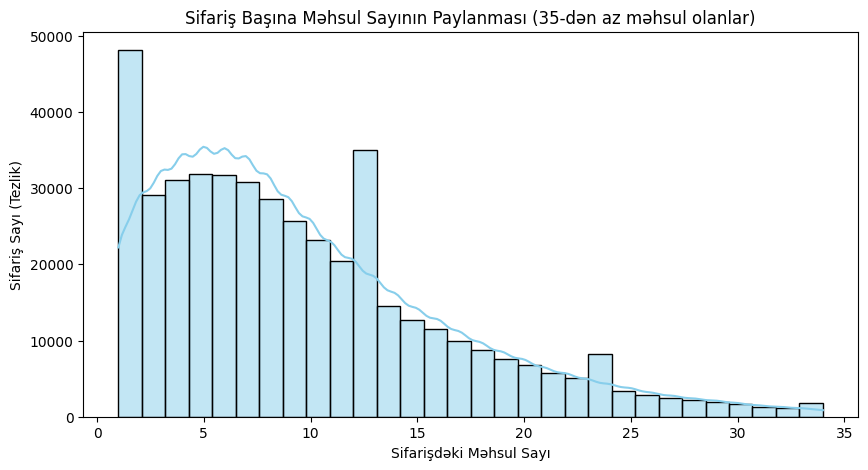

In [75]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))
sns.histplot(filtered_order_sizes, kde=True, bins=30, color='skyblue')

plt.title('Sifariş Başına Məhsul Sayının Paylanması (35-dən az məhsul olanlar)')
plt.xlabel('Sifarişdəki Məhsul Sayı')
plt.ylabel('Sifariş Sayı (Tezlik)')
plt.show()

###***Qrafikdən görünür ki, sifarişlərin böyük əksəriyyəti azsaylı məhsullardan ibarətdir və ən yüksək aralıq 1–7 məhsul aralığıdır. həmçinin 12 13 aralığında məhsul da daha çox sifariş edilir***.


### ***[C2] Ən çox yenidən sifariş edilən 20 məhsulu tapaq və ekrana adlarını və id lərini çıxaraq***

### ***Bunun üçün order_products və products cədvəllərindən istifadə edəcəyik***

In [76]:
# Əvvəlcə reorder yalnız 1 olanları seçirik

yeniden_sifaris_edilenler=order_products[order_products['reordered']==1]

# daha sonra value_counts() ilə bu məhsulları sayırıq ilk 20 dənəsini ekrana çıxarırıq. series qaytarmasın deyə sonuna reset_index() yazıb data frame edirik

yeniden_sifaris_top_20=yeniden_sifaris_edilenler['product_id'].value_counts().head(20).reset_index()
yeniden_sifaris_top_20

# Indi isə aldığımız cədvəllə products cədvəlini merge() ilə birləşdirək

umumi_cedvel=yeniden_sifaris_top_20.merge(products, on='product_id')
umumi_cedvel


,product_id,count,product_name,aisle_id,department_id
0,24852,55763,Banana,24,4
1,13176,44450,Bag of Organic Bananas,24,4
2,21137,28639,Organic Strawberries,24,4
3,21903,26233,Organic Baby Spinach,123,4
4,47209,23629,Organic Hass Avocado,24,4
5,47766,18743,Organic Avocado,24,4
6,27845,16251,Organic Whole Milk,84,16
7,47626,15044,Large Lemon,24,4
8,27966,14748,Organic Raspberries,123,4
9,16797,13945,Strawberries,24,4


### ***Deməli həm ən çox sifariş olunan(66050) və ən çox təkrar sifariş olunan (55763) məhsul banandır. həmçinin bu 20 məhsulun əksəriyyəti meyvə tərəvəzdir. demeli insanlar hər alış-verişlərinə meyvə tərəvəz əlavə edirlər***


###***[C3] Hər bir məhsul üçün sifarişlərin neçə faizi təkrar sifarişlərdir?***

In [77]:
# hər mehsul üçün reorder sütunnun orta qiymetini tapırıq və 100 e vururuq

tekrar_mehsul_faizi= order_products.groupby('product_id')['reordered'].mean() * 100
tekrar_mehsul_faizi

# sonuna reset_index() yazaq df olsun
tekrar_mehsul_faizi = tekrar_mehsul_faizi .reset_index(name='reorder_percentage')

# çoxdan aza sıralayaq
tekrar_mehsul_faizi  = tekrar_mehsul_faizi .sort_values(by='reorder_percentage', ascending=False)

tekrar_mehsul_faizi

,product_id,reorder_percentage
28108,30644,100.0
7340,8054,100.0
28114,30650,100.0
41002,44747,100.0
40998,44743,100.0
...,...,...
22644,24675,0.0
22645,24676,0.0
22654,24688,0.0
10300,11290,0.0



### ***[C4] Hər bir müştəri üçün sifariş edilən məhsulların hansı hissəsi təkrar sifariş olduğunu araşdıraq***

### ***Bunun üçün orders_product və orders cedvəllərindən istifadə edəcəyik***

In [78]:
# Əvvəlcə hər iki cədəvli birləşdirək

general_table=orders.merge(order_products, on='order_id')

# Daha sonra groupby() istifadə edək
tekrar_sifaris=general_table.groupby(['user_id', 'reordered'])['product_id'].sum().reset_index()
tekrar_sifaris


,user_id,reordered,product_id
0,2,0,775532
1,2,1,32792
2,4,0,49489
3,5,0,52887
4,5,1,191234
...,...,...,...
274510,206207,1,1149027
274511,206208,0,951996
274512,206208,1,2214329
274513,206209,0,387640



### ***[C5] İnsanların səbətlərinə ilk olaraq qoyduqları ən çox istifadə etdikləri 20 məhsulu araşdıraq***

In [79]:
# əvvəlcə add_to_cart_order ==1 olanları seçirik

ilk_qoyulanlar=order_products[order_products['add_to_cart_order']==1]
ilk_qoyulanlar

# Daha sonra bu cədvəldə product_id ləri hesablayırıq ilk 20 sini ekrana gətiririk

top20_ilk_mehsul=ilk_qoyulanlar['product_id'].value_counts().head(20).reset_index()
top20_ilk_mehsul

# Indi isə merge() ile products cedveli ile top20_ilk_mehsul cedvelini birleşdirek

merged=products.merge(top20_ilk_mehsul, on='product_id')
merged

# Sort_values() ilƏ çoxdan aza yazdıraq
merged.sort_values(by='count', ascending=False)

,product_id,product_name,aisle_id,department_id,count
9,24852,Banana,24,4,15562
3,13176,Bag of Organic Bananas,24,4,11026
12,27845,Organic Whole Milk,84,16,4363
6,21137,Organic Strawberries,24,4,3946
16,47209,Organic Hass Avocado,24,4,3390
7,21903,Organic Baby Spinach,123,4,3336
18,47766,Organic Avocado,24,4,3044
5,19660,Spring Water,115,7,2336
4,16797,Strawberries,24,4,2308
13,27966,Organic Raspberries,123,4,2024


### ***Səbətə ilk olaraq ən çox əlavə edilən məhsullar tərəvəz/meyvə, süd məhsulları və qazlı su və ya adi su kimi içkilərdir. Instacart tətbiqindən istifadə təcrübəm olmadan bunun səbəbini dəqiq deyə bilmərəm, çünki bu, məhsulların xüsusiyyətlərindən daha çox tətbiqin dizaynı ilə bağlı ola bilər. Lakin fikir verirəm ki, bu nəticə ilə ən populyar və ən çox təkrar sifariş edilən məhsul növləri üzrə əvvəlki nəticə arasında ciddi üst-üstə düşmə var. Bu, sadəcə tətbiqin populyar məhsulları ilk təklif olunan alverlər kimi ön plana çıxarmasından da qaynaqlana bilər; nəticədə alıcılar üçün bu məhsulları səbətə ilk olaraq əlavə etmək daha rahat olur.***

###***[Stats1]: orders məlumat çərçivəsindəki (dataframe) əsas ədədi sütunlar (məsələn, order_hour_of_day, days_since_prior_order) üçün təsviri statistik göstəriciləri (descriptive statistics) hesablayın. .describe() metodundan istifadə edin və orta qiyməti (mean), medianı (median), standart meyli (standard deviation), minimumu (min) və maksimumu (max) müştərilərin sifariş etmə davranışı kontekstində şərh edin.***

In [80]:
orders

,order_id,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order
0,1515936,183418,11,6,13,30
1,1690866,163593,5,5,12,9
2,1454967,39980,4,5,19,2
3,1768857,82516,56,0,20,10
4,3007858,196724,2,4,12,17
...,...,...,...,...,...,...
478962,3210681,5617,5,1,14,7
478963,3270802,112087,2,3,13,6
478964,885349,82944,16,2,11,6
478965,216274,4391,3,3,8,8


In [81]:
orders['order_dow'].describe()

,order_dow
count,478952.000000
mean,2.775051
std,2.045901
min,0.000000
25%,1.000000
50%,3.000000
75%,5.000000
max,6.000000


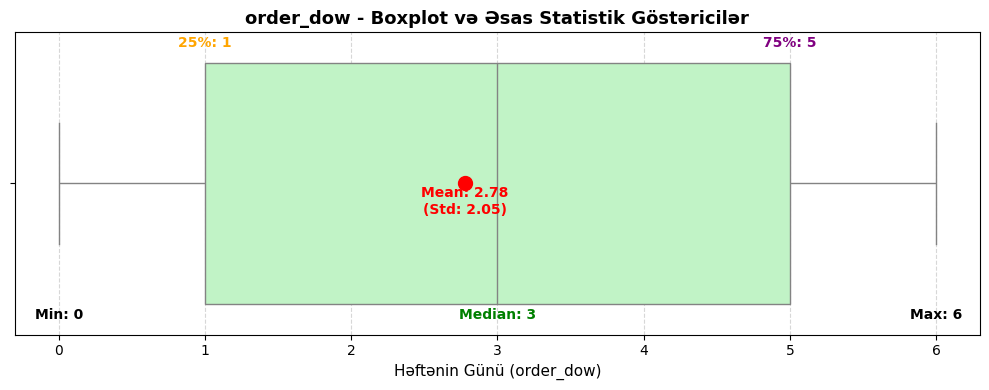

In [82]:
stats = orders['order_dow'].describe()

plt.figure(figsize=(10, 4))

# Horizontal Boxplot
sns.boxplot(x=orders['order_dow'], color='#b9fbc0', showmeans=True,
            meanprops={"marker":"o", "markerfacecolor":"red", "markeredgecolor":"red", "markersize":"10"})

# Dəyərləri qrafik üzərində mətn olaraq yazdırırıq
y_pos = 0.45
plt.text(stats['min'], y_pos, f"Min: {stats['min']:.0f}", horizontalalignment='center', color='black', fontweight='bold')
plt.text(stats['25%'], -0.45, f"25%: {stats['25%']:.0f}", horizontalalignment='center', color='orange', fontweight='bold')
plt.text(stats['50%'], y_pos, f"Median: {stats['50%']:.0f}", horizontalalignment='center', color='green', fontweight='bold')
plt.text(stats['75%'], -0.45, f"75%: {stats['75%']:.0f}", horizontalalignment='center', color='purple', fontweight='bold')
plt.text(stats['max'], y_pos, f"Max: {stats['max']:.0f}", horizontalalignment='center', color='black', fontweight='bold')
plt.text(stats['mean'], 0.1, f"Mean: {stats['mean']:.2f}\n(Std: {stats['std']:.2f})", horizontalalignment='center', color='red', fontweight='bold')

plt.title("order_dow - Boxplot və Əsas Statistik Göstəricilər", fontsize=13, fontweight='bold')
plt.xlabel("Həftənin Günü (order_dow)", fontsize=11)
plt.xticks(range(0, 7))
plt.grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

###" ***order_dow sutunnunun təhlili göstərir ki sifarişlər həftənin 0 dan 6 ya qədər olan bütun günlərinə yayılmışdır. Orta sifariş günü 2.78 median isə 3.0a bərabərdir. Bu göstəricilər məlumatın simmetrik paylandığını və müştərin həftə boyunca aktif oldugunu göstərir. Sifarişlərin mühim 50% lik hissəsi 1ci və 5ci günlər aralığında toplanmışdır."***

###***"[Stats5]: Daha yaxşı vizuallaşdırma üçün seaborn kitabxanasından istifadə edərək order_hour_of_day sütunu üçün histoqram qurun. Bunu [A1] tapşırığındakı matplotlib versiyası ilə müqayisə edin və piki təşkil edən sifariş saatları barədə fikirlərinizi (məsələn, əhalinin/müştərilərin davranışı ilə əlaqələndirərək) müzakirə edin."***

In [83]:
orders['order_hour_of_day'].describe()

,order_hour_of_day
count,478952.000000
mean,13.447034
std,4.224567
min,0.000000
25%,10.000000
50%,13.000000
75%,16.000000
max,23.000000


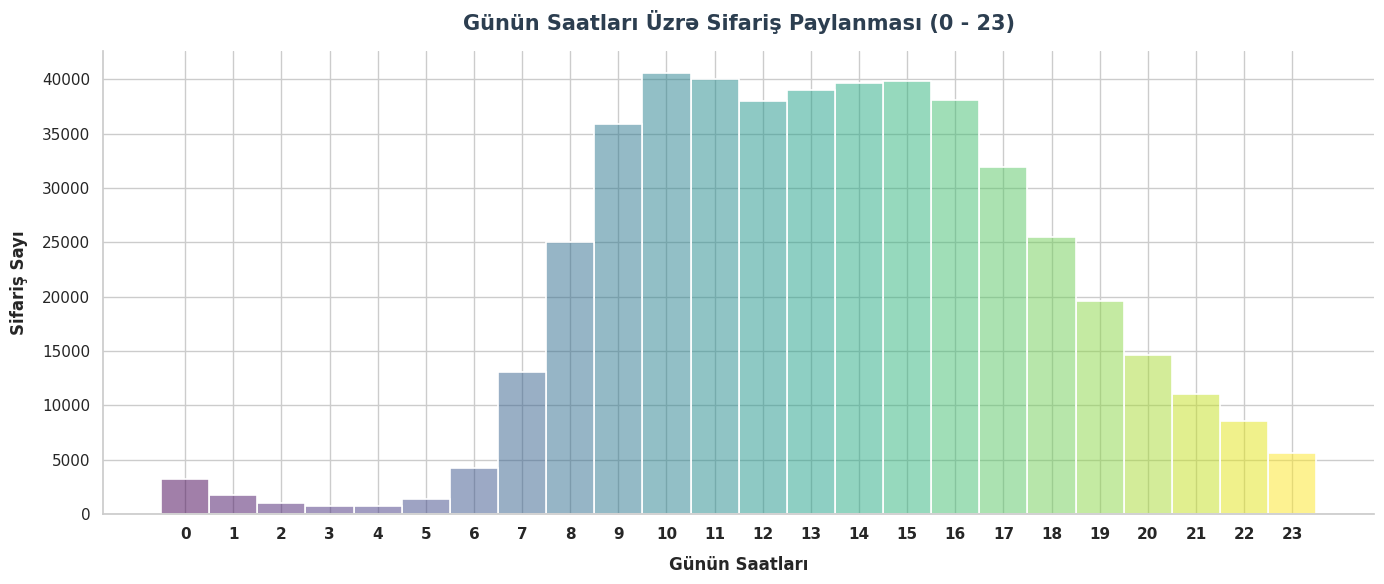

In [84]:
# Görünüş stilini təyin edirik
sns.set_theme(style="whitegrid")

plt.figure(figsize=(14, 6))

# Rəngli və estetik Seaborn histoqramı
ax = sns.histplot(
    data=orders,
    x='order_hour_of_day',
    discrete=True,
    hue='order_hour_of_day',   # Hər saat üçün fərqli rəng tonu
    palette='viridis',          # 'coolwarm', 'magma', 'rocket' və ya 'spectral' istifadə edə bilərsiniz
    legend=False,
    edgecolor='white',
    linewidth=1.2
)

# X oxundakı bölgüləri dəqiq 0 və 23 arası edirik
plt.xticks(range(0, 24), fontsize=11, fontweight='bold')
plt.yticks(fontsize=11)

# Başlıq və ox adları
plt.title('Günün Saatları Üzrə Sifariş Paylanması (0 - 23)', fontsize=15, fontweight='bold', pad=15, color='#2c3e50')
plt.xlabel('Günün Saatları', fontsize=12, fontweight='bold', labelpad=10)
plt.ylabel('Sifariş Sayı', fontsize=12, fontweight='bold', labelpad=10)

# Üst və sağ çərçivə xətlərini təmizləyirik
sns.despine()

plt.tight_layout()
plt.show()

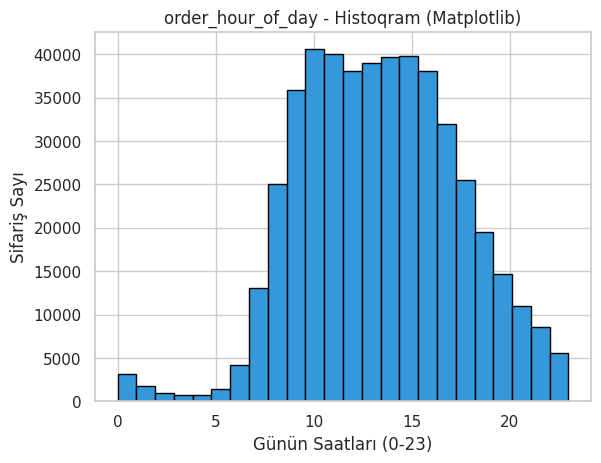

In [85]:
import matplotlib.pyplot as plt

# Matplotlib histoqramı
plt.hist(orders['order_hour_of_day'], bins=24, range=(0, 23), color='#3498db', edgecolor='black')

plt.title('order_hour_of_day - Histoqram (Matplotlib)')
plt.xlabel('Günün Saatları (0-23)')
plt.ylabel('Sifariş Sayı')

plt.show()

### ***Bu swtunun analizi göstərir ki sifarişlər günün bütün saatlarına yayılmışdır. lakin ən aktif saatlar 10 və 15 aralığıdır .histogram qrafikindən baxıb deyə bilərik ki ortalama olaraq nahar ərəfəsində  tətbiqdən istifadə artır seaborn qrafiki matplotlip qrafikinə nisbətən vizual olaraq daha rəngli və cəlbedici qrafiklər qurmağa imkan verir.**

###"***[Stats1]: seaborn və ya matplotlib kitabxanasından istifadə edərək days_since_prior_order sütununun paylanmasını boxplot (qutu qrafiki) vasitəsilə vizuallaşdırın. Kənar dəyərləri (outliers) müəyyən edin və onların müştəri davranışı baxımından nəyi ifadə edə biləcəyini (məsələn, sifarişlər arasındakı uzun fasilələri) müzakirə edin."***

In [86]:
orders['days_since_prior_order'].describe()

,days_since_prior_order
count,450135.0
mean,11.101814
std,9.190004
min,0.0
25%,4.0
50%,7.0
75%,15.0
max,30.0


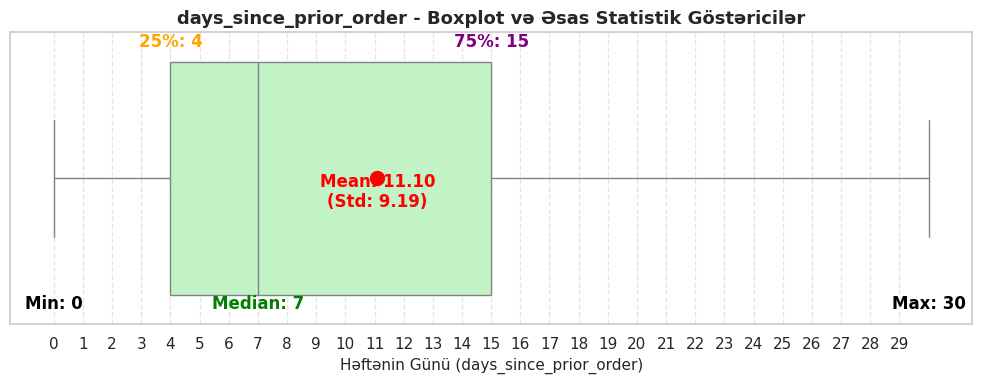

In [87]:
stats = orders['days_since_prior_order'].describe()

plt.figure(figsize=(10, 4))

# Horizontal Boxplot
sns.boxplot(x=orders['days_since_prior_order'], color='#b9fbc0', showmeans=True,
            meanprops={"marker":"o", "markerfacecolor":"red", "markeredgecolor":"red", "markersize":"10"})

# Dəyərləri qrafik üzərində mətn olaraq yazdırırıq
y_pos = 0.45
plt.text(stats['min'], y_pos, f"Min: {stats['min']:.0f}", horizontalalignment='center', color='black', fontweight='bold')
plt.text(stats['25%'], -0.45, f"25%: {stats['25%']:.0f}", horizontalalignment='center', color='orange', fontweight='bold')
plt.text(stats['50%'], y_pos, f"Median: {stats['50%']:.0f}", horizontalalignment='center', color='green', fontweight='bold')
plt.text(stats['75%'], -0.45, f"75%: {stats['75%']:.0f}", horizontalalignment='center', color='purple', fontweight='bold')
plt.text(stats['max'], y_pos, f"Max: {stats['max']:.0f}", horizontalalignment='center', color='black', fontweight='bold')
plt.text(stats['mean'], 0.1, f"Mean: {stats['mean']:.2f}\n(Std: {stats['std']:.2f})", horizontalalignment='center', color='red', fontweight='bold')

plt.title("days_since_prior_order - Boxplot və Əsas Statistik Göstəricilər", fontsize=13, fontweight='bold')
plt.xlabel("Həftənin Günü (days_since_prior_order)", fontsize=11)
plt.xticks(range(0, 30))
plt.grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### ***Qrafikdən görünür ki, bir sonraki sifarişə qədər olan vaxt 0 ilə 30 gün arasında paylanıb və istifadəçilərin 50% i 4 15 gün sonra təkrar sifarış etmişlər. Medianın 7 gün olması həftəlik alış veriş edənlərin sayının daha çox olduğunu göstərir lakim ortalamanın 11 gwn olması ayda bir dəfə sifariş verən nadir muştərilərə görədir ki ortalama dəyərin artmasına səbəb olub.30 günlük yuxarı həddə toplanan müştərilərə aktivliyi artırmaq üçün son sifarişindən 14 gün keçdikdən sonra xüsusi xatırlatma bildirişləri və ya həvəsləndirici endirimlər təqdim olunmalıdır.***

###***Statistika terminlərinin (məsələn: ədədi orta, variasiya, korrelyasiya) verilənləri anlamağa necə kömək etdiyini müzakirə edin. (Hər hansı bir və ya bir neçə sütun götürün; ədədi ortanı, dispersiyanı və korrelyasiyanı tapın və nəticələrinizi izah edin.)***

###***Statistika terminləri bizə xam verilənlər cədvəlinə baxarkən gözlə görə bilmədiyimiz qanunauyğunluqları tapmağa kömək edir. Ədədi orta müştərilərin tipik davranış vaxtını, Variasiya müştərilərin nə dərəcədə fərqli tezliklərlə alış-veriş etdiyini, korrelyasiya isə müştəri loyallığı ilə alış tezliyi arasındakı asılılığı anlamağa imkan verir.***

In [88]:
# 1 Mean
mean_hour = orders['order_hour_of_day'].mean()
mean_days = orders['days_since_prior_order'].mean()

print(f'order_hour_of_day Ədədi Orta: {mean_hour}')
print(f'days_since_prior_order Ədədi orta: {mean_days}')

# 2.Variance
var_hour = orders['order_hour_of_day'].var()
var_days = orders['days_since_prior_order'].var()

print(f'order_hour_of_day Variasiya: {var_hour}')
print(f'days_since_prior_order Variasiya: {var_days}')

order_hour_of_day Ədədi Orta: 13.447034358349063
days_since_prior_order Ədədi orta: 11.101813900274362
order_hour_of_day Variasiya: 17.84696214769903
days_since_prior_order Variasiya: 84.45616609487577


In [89]:
# 3. Correlation
correlation = orders[[ 'order_hour_of_day', 'days_since_prior_order']].corr()
print(f'Korelasiya: {correlation}')

Korelasiya:                         order_hour_of_day  days_since_prior_order
order_hour_of_day                1.000000               -0.002509
days_since_prior_order          -0.002509                1.000000


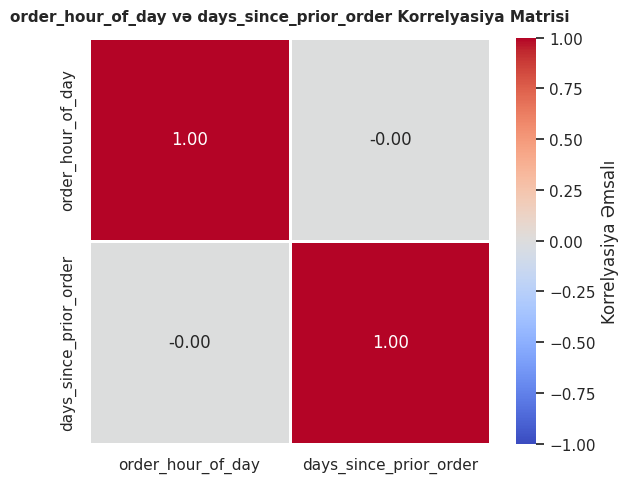

In [90]:
# 1. Seçilmiş 2 Sütun üzrə Korrelyasiya Matrisinin hesablanması
cols = ['order_hour_of_day', 'days_since_prior_order']
correlation = orders[cols].corr()

# 2. Qrafikin ölçüsü
plt.figure(figsize=(6, 5))

# 3. Korrelyasiya İstilik Xəritəsi (Heatmap)
sns.heatmap(
    correlation,
    annot=True,  # Xanaların daxilində ədədləri göstərir
    fmt='.2f',  # Ədədləri 2 onluq dəqiqliklə göstərir
    cmap='coolwarm',  # Vizual rəng palitrası
    vmin=-1,
    vmax=1,  # Skala aralığı (-1 ilə +1)
    linewidths=1,  # Xanalar arası separator xətti
    cbar_kws={'label': 'Korrelyasiya Əmsalı'},
)

# 4. Başlıq və oxların nizamlanması
plt.title(
    'order_hour_of_day və days_since_prior_order Korrelyasiya Matrisi',
    fontsize=11,
    fontweight='bold',
    pad=12,
)
plt.tight_layout()

# 5. Qrafiki ekrana çıxarmaq
plt.show()

###Bu iki dəyişən arasında heç bir asılılıq yoxdur. Yəni müştərinin günün hansı saatında sifariş verməsi onun növbəti sifarişi neçə gün sonra edəcəyinə heç bir təsir göstərmir. Bu iki davranış bir-birindən tamamilə ayrıdır.